# 01 · Data curation and fixed splits

Input: `data/raw/will_it_fly_in_mass_spec.tsv` (Zenodo 21450795).
Output: `data/processed/wif_curated.csv`, one row per compound with labels, censoring flags and split columns.
Every model in this project uses these exact rows and splits.

Decisions made here:
- **Label**: flies if peak area > 10,000 (reproduces the reported 52.9% formate / 78.6% fluoride pass rates).
- **Zeros**: area = 0 means "no peak found"; kept as left-censored values for the Tobit model (Model 2), and as "does not fly" for the yes/no label.
- **Stereoisomers**: grouped by the first 14 characters of the InChIKey (same skeleton), so a pair never ends up split between train and test.
- **Test set**: 20%, frozen. Two versions: random, and cluster-based (whole clusters of similar molecules held out).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from rdkit.SimDivFilters import rdSimDivPickers

RDLogger.DisableLog("rdApp.*")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "will_it_fly_in_mass_spec.tsv"
OUT = ROOT / "data" / "processed" / "wif_curated.csv"

CUTOFF = 10_000        # area threshold for "flies"
TEST_FRAC = 0.20
N_FOLDS = 5
CLUSTER_SIM = 0.40     # Tanimoto similarity defining a cluster (distance 0.6)
SEED = 20261124

## 1. Load and check structures

In [2]:
raw = pd.read_csv(RAW, sep="\t")
print(raw.shape)

df = pd.DataFrame({
    "compound_id": raw["ocnt_batch"],
    "smiles": raw["standardized_smiles"],
    "area_formate": raw["ammonium_formate_area"],
    "area_fluoride": raw["ammonium_fluoride_area"],
})

mols = [Chem.MolFromSmiles(s) for s in df["smiles"]]
assert all(m is not None for m in mols), "unparseable SMILES"
df["inchikey"] = [Chem.MolToInchiKey(m) for m in mols]
df["skeleton_key"] = df["inchikey"].str[:14]          # ignores stereo / isotopes
df["heavy_atoms"] = [m.GetNumHeavyAtoms() for m in mols]
df["permanent_charge"] = [any(a.GetFormalCharge() != 0 for a in m.GetAtoms()) for m in mols]

print("duplicate IDs:      ", df["compound_id"].duplicated().sum())
print("duplicate InChIKeys:", df["inchikey"].duplicated().sum())
print("stereo groups (>1): ", (df["skeleton_key"].value_counts() > 1).sum())
print("permanently charged:", df["permanent_charge"].sum())

(11353, 4)
duplicate IDs:       0
duplicate InChIKeys: 1
stereo groups (>1):  13
permanently charged: 105


## 2. Labels and censoring

`log10_area_*` is NaN where area = 0; `censored_*` marks those rows for the Tobit likelihood.
The smallest non-zero area is ~20, so zeros sit below an implied detection limit.

In [3]:
for k in ["formate", "fluoride"]:
    a = df[f"area_{k}"]
    df[f"censored_{k}"] = a == 0
    df[f"log10_area_{k}"] = np.log10(a.where(a > 0))
    df[f"flies_{k}"] = (a > CUTOFF).astype(int)
    print(f"{k:8s}  flies {df[f'flies_{k}'].mean():.1%}   zeros {df[f'censored_{k}'].sum():4d}   min>0 {a[a > 0].min():.0f}")

formate   flies 52.9%   zeros  362   min>0 20
fluoride  flies 78.6%   zeros  208   min>0 29


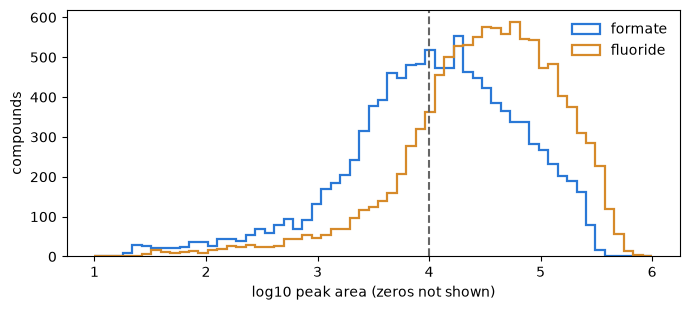

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(1, 6, 60)
for k, c in [("formate", "#2a78d6"), ("fluoride", "#d68a2a")]:
    ax.hist(df[f"log10_area_{k}"].dropna(), bins=bins, histtype="step", lw=1.6, color=c, label=k)
ax.axvline(np.log10(CUTOFF), ls="--", color="0.4")
ax.set_xlabel("log10 peak area (zeros not shown)"); ax.set_ylabel("compounds"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Clusters for the cluster-based split

Morgan fingerprints (radius 2, 2048 bits), then sphere exclusion (Leader picker) chooses cluster centres at Tanimoto distance 0.6, and every molecule joins its nearest centre.
Stereo pairs are forced into the same cluster.

In [5]:
fpg = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [fpg.GetFingerprint(m) for m in mols]

picker = rdSimDivPickers.LeaderPicker()
centres = list(picker.LazyBitVectorPick(fps, len(fps), 1 - CLUSTER_SIM))   # deterministic: walks the file order
centre_fps = [fps[i] for i in centres]
df["cluster"] = [int(np.argmax(DataStructs.BulkTanimotoSimilarity(fp, centre_fps))) for fp in fps]

# keep stereo pairs together: every member of a skeleton group takes the first member's cluster
df["cluster"] = df.groupby("skeleton_key")["cluster"].transform("first")

sizes = df["cluster"].value_counts()
print(f"{len(sizes)} clusters; singletons {(sizes == 1).sum()}; largest {sizes.max()}")

7067 clusters; singletons 4583; largest 23


## 4. Frozen splits

- `split_random`: 20% test, groups = stereo skeleton, balanced on the formate label.
- `split_cluster`: 20% test made of whole clusters, balanced on the formate label.
- `fold_random` / `fold_cluster`: 5 CV folds inside each training set (-1 for test rows).

In [6]:
rng = np.random.default_rng(SEED)

def group_split(groups, strat, frac, rng):
    """Pick whole groups for test until `frac` of rows, separately within each label so the pass rate stays balanced."""
    g = pd.DataFrame({"g": groups, "y": strat})
    gy = g.groupby("g")["y"].agg(lambda s: s.mode()[0])     # majority label of each group
    counts = g["g"].value_counts()
    chosen = []
    for y in sorted(gy.unique()):
        ids = gy.index[gy == y].to_numpy().copy()
        rng.shuffle(ids)
        target, n = frac * counts[ids].sum(), 0
        for i in ids:
            if n >= target:
                break
            chosen.append(i)
            n += counts[i]
    return g["g"].isin(chosen).to_numpy()

def group_folds(groups, k, rng):
    ids = pd.unique(groups).copy()
    rng.shuffle(ids)
    fold_of = {gid: i % k for i, gid in enumerate(ids)}
    return np.array([fold_of[gid] for gid in groups])

y = df["flies_formate"].to_numpy()
test_r = group_split(df["skeleton_key"].to_numpy(), y, TEST_FRAC, rng)
test_c = group_split(df["cluster"].to_numpy(), y, TEST_FRAC, rng)
df["split_random"] = np.where(test_r, "test", "train")
df["split_cluster"] = np.where(test_c, "test", "train")

for name, test, grp in [("random", test_r, "skeleton_key"), ("cluster", test_c, "cluster")]:
    f = np.full(len(df), -1)
    f[~test] = group_folds(df.loc[~test, grp].to_numpy(), N_FOLDS, rng)
    df[f"fold_{name}"] = f

summary = pd.concat({s: df.groupby(f"split_{s}").agg(n=("compound_id", "size"),
                                                     flies_formate=("flies_formate", "mean"),
                                                     flies_fluoride=("flies_fluoride", "mean"))
                     for s in ["random", "cluster"]})
print(summary.round(3))

                         n  flies_formate  flies_fluoride
        split_random                                     
random  test          2271          0.529           0.792
        train         9082          0.529           0.784
cluster test          2271          0.531           0.779
        train         9082          0.528           0.787


In [7]:
# sanity checks: no group crosses train/test
for scheme, grp in [("split_random", "skeleton_key"), ("split_cluster", "cluster"), ("split_cluster", "skeleton_key")]:
    assert df.groupby(grp)[scheme].nunique().max() == 1, (scheme, grp)

# how far is each test molecule from its nearest training neighbour?
def nn_sim(test):
    train_fps = [fps[i] for i in np.where(~test)[0]]
    return np.array([max(DataStructs.BulkTanimotoSimilarity(fps[i], train_fps)) for i in np.where(test)[0]])
print(f"median nearest-train Tanimoto: random test {np.median(nn_sim(test_r)):.2f}, cluster test {np.median(nn_sim(test_c)):.2f}")

median nearest-train Tanimoto: random test 0.42, cluster test 0.38


## 5. Optional: flag the 1342 XenoSite parents

These live in the old OpenADMET folder, outside this repo. If the files are missing the column is skipped, not filled with False.

In [8]:
PARENT_FILES = [Path(r"D:\OpenADMET\parent_compounds.csv"), Path(r"D:\OpenADMET\remaining_parent_compounds.csv")]
if all(p.exists() for p in PARENT_FILES):
    parents = pd.concat([pd.read_csv(p) for p in PARENT_FILES], ignore_index=True)
    pkeys = {Chem.MolToInchiKey(m)[:14] for m in map(Chem.MolFromSmiles, parents["smiles"]) if m is not None}
    pids = {c.rsplit("-", 2)[0] for c in parents["compound_id"]}
    df["in_parents_1342"] = df["skeleton_key"].isin(pkeys) | df["compound_id"].str.rsplit("-", n=2).str[0].isin(pids)
    print(f"{len(parents)} parents -> {df['in_parents_1342'].sum()} Will It Fly rows match")
    print(pd.crosstab(df["in_parents_1342"], [df["split_random"], df["split_cluster"]]))
else:
    print("parent files not found; skipping in_parents_1342")

1342 parents -> 45 Will It Fly rows match
split_random    test       train      
split_cluster   test train  test train
in_parents_1342                       
False            432  1827  1835  7214
True               0    12     4    29


## 6. Save

In [9]:
cols = ["compound_id", "smiles", "inchikey", "skeleton_key", "heavy_atoms", "permanent_charge",
        "area_formate", "area_fluoride", "log10_area_formate", "log10_area_fluoride",
        "censored_formate", "censored_fluoride", "flies_formate", "flies_fluoride",
        "cluster", "split_random", "fold_random", "split_cluster", "fold_cluster"]
cols += [c for c in ["in_parents_1342"] if c in df]
OUT.parent.mkdir(parents=True, exist_ok=True)
df[cols].to_csv(OUT, index=False)
print(OUT, df[cols].shape)

d:\Bayesian\data\processed\wif_curated.csv (11353, 20)
